In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler


sns.set_style("whitegrid")

In [2]:
import pandas as pd

df = pd.read_csv("creditcard1.csv")
print (df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Dataset Overview
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [5]:
# Missing Value Analysis
print("Total Missing Value:", df.isnull().sum().sum())

Total Missing Value: 0


<Axes: >

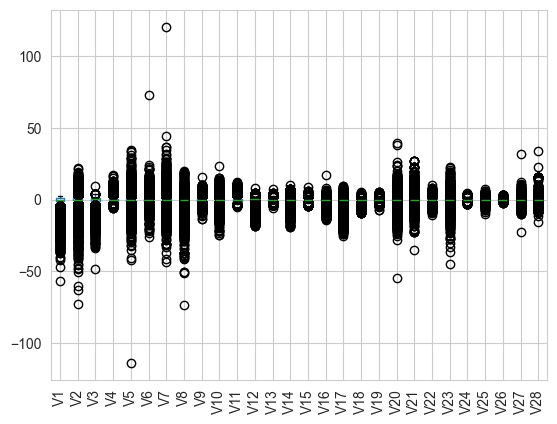

In [6]:
df.drop(columns=['Class','Time','Amount']).boxplot(rot=90)

In [7]:
df[['Time','Amount']].boxplot()

<Axes: >

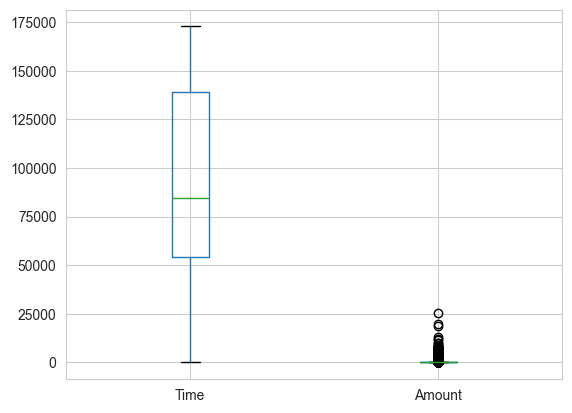

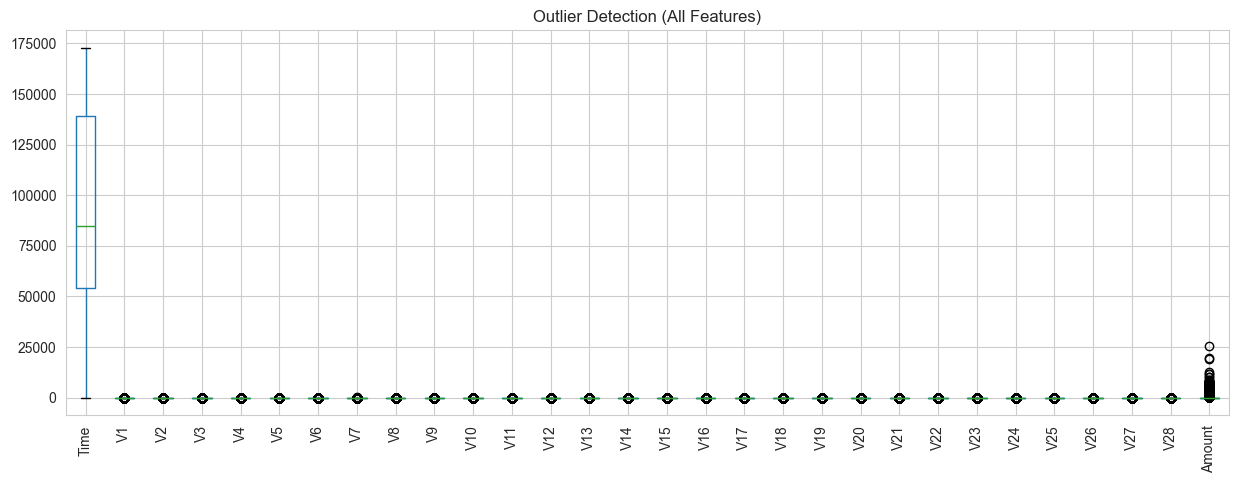

In [8]:
# Outlier Analysis
plt.figure(figsize=(15,5))
df.drop(columns=['Class']).boxplot(rot=90)
plt.title("Outlier Detection (All Features)")
plt.show()

In [9]:
outlier_counts = {}
for col in df.drop(columns=['Class']).columns:
    
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    outlier_counts[col] = len(outliers)

pd.Series(outlier_counts).sort_values(ascending=False)

V27       39163
Amount    31904
V28       30342
V20       27770
V8        24134
V6        22965
V23       18541
V12       15348
V21       14497
V14       14149
V2        13526
V5        12295
V4        11148
V19       10205
V10        9496
V7         8948
V9         8283
V16        8184
V18        7533
V17        7420
V1         7062
V26        5596
V25        5367
V24        4774
V13        3368
V3         3363
V15        2894
V22        1317
V11         780
Time          0
dtype: int64

In [10]:
# Constant Feature Analysis
[col for col in df.columns if df[col].nunique() == 1]

[]

In [11]:
df.nunique()

Time      124592
V1        275663
V2        275663
V3        275663
V4        275663
V5        275663
V6        275663
V7        275663
V8        275663
V9        275663
V10       275663
V11       275663
V12       275663
V13       275663
V14       275663
V15       275663
V16       275663
V17       275663
V18       275663
V19       275663
V20       275663
V21       275663
V22       275663
V23       275663
V24       275663
V25       275663
V26       275663
V27       275663
V28       275663
Amount     32767
Class          2
dtype: int64

In [12]:
# Cek Feature Range
feature_range = df.drop(columns=['Class']).agg(['min','max']).T
feature_range

,min,max
Time,0.000000,172792.000000
V1,-56.407510,2.454930
V2,-72.715728,22.057729
V3,-48.325589,9.382558
V4,-5.683171,16.875344
V5,-113.743307,34.801666
V6,-26.160506,73.301626
V7,-43.557242,120.589494
V8,-73.216718,20.007208
V9,-13.434066,15.594995


In [13]:
#cek distribusi kelas
print(df['Class'].value_counts())
print("\nPersentase :")
print(df['Class'].value_counts(normalize=True) * 100)


Class
0    284315
1       492
Name: count, dtype: int64

Persentase :
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [14]:
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

print("\nNama fitur:")
print(df.columns.tolist())

Jumlah baris: 284807
Jumlah kolom: 31

Nama fitur:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


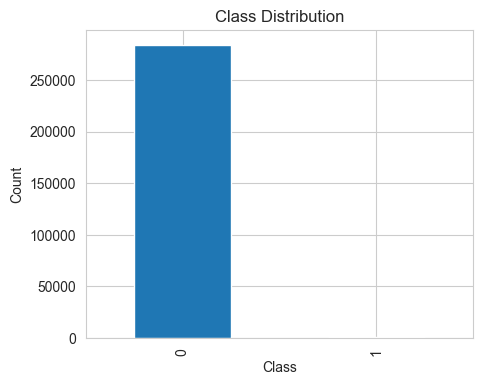

In [15]:
plt.figure(figsize=(5,4))

df['Class'].value_counts().plot(kind='bar')

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

**PREPROCESSING**

In [25]:
# pisahkan fitur dan label
X = df.drop('Class', axis=1)
y = df['Class']

**1.Feature Scaling (Z-Normalization)**

In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [27]:
X_scaled.min()
X_scaled.max()

np.float64(102.54342136221207)

In [28]:
x_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled.mean(axis=0)

array([-3.06563713e-16, -1.50687242e-17, -9.58011603e-18, -8.62210442e-17,
       -5.18922951e-18,  3.83204641e-17,  9.97928753e-18,  1.23743165e-17,
       -3.19337201e-18,  7.23498346e-19,  5.58840102e-18, -4.31105221e-17,
        1.67652030e-17, -1.25240058e-17,  2.59461476e-17, -2.07569181e-17,
        1.83618891e-17,  3.39295776e-18,  2.63453191e-17,  4.36593829e-18,
       -1.24741094e-18, -3.64243995e-18,  3.19337201e-18,  8.78177302e-18,
        9.58011603e-18, -5.02956091e-17,  5.88777964e-18,  2.44492544e-18,
       -7.90858537e-18,  2.91395196e-17])

In [29]:
x_scaled.std()

Time      1.000002
V1        1.000002
V2        1.000002
V3        1.000002
V4        1.000002
V5        1.000002
V6        1.000002
V7        1.000002
V8        1.000002
V9        1.000002
V10       1.000002
V11       1.000002
V12       1.000002
V13       1.000002
V14       1.000002
V15       1.000002
V16       1.000002
V17       1.000002
V18       1.000002
V19       1.000002
V20       1.000002
V21       1.000002
V22       1.000002
V23       1.000002
V24       1.000002
V25       1.000002
V26       1.000002
V27       1.000002
V28       1.000002
Amount    1.000002
dtype: float64

In [30]:
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

**2. Membagi Data Training dan Testing Menggunakan K-Fold**

**3. Resampling (SMOTE)**

In [31]:
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

smote = SMOTE(random_state=42)

for train_index, test_index in skf.split(X_scaled, y):

    X_train, X_test = X_scaled.iloc[train_index], X_scaled.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # SMOTE hanya pada data training
    X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

    print("Before SMOTE:", X_train.shape)
    print("After SMOTE:", X_train_res.shape)

Before SMOTE: (227845, 30)
After SMOTE: (454904, 30)
Before SMOTE: (227845, 30)
After SMOTE: (454904, 30)
Before SMOTE: (227846, 30)
After SMOTE: (454904, 30)
Before SMOTE: (227846, 30)
After SMOTE: (454904, 30)
Before SMOTE: (227846, 30)
After SMOTE: (454904, 30)


In [34]:
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
import tensorflow as tf

# jumlah fitur
input_dim = X_train_res.shape[1]

input_layer = Input(shape=(input_dim,))

# Encoder
encoded = Dense(512, activation="relu", kernel_regularizer=l2(0.0001))(input_layer)
encoded = Dropout(0.2)(encoded)

encoded = Dense(256, activation="relu", kernel_regularizer=l2(0.0001))(encoded)
encoded = Dropout(0.2)(encoded)

encoded = Dense(128, activation="relu", kernel_regularizer=l2(0.0001))(encoded)

# Decoder
decoded = Dense(256, activation="relu")(encoded)
decoded = Dense(512, activation="relu")(decoded)

decoded = Dense(input_dim, activation="linear")(decoded)

autoencoder = Model(inputs=input_layer, outputs=decoded)

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="mse"
)

In [35]:
history = autoencoder.fit(
    X_train_res,
    X_train_res,
    epochs=50,
    batch_size=64,
    validation_split=0.2,
    shuffle=True
)

Epoch 1/50
5687/5687 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 0.4224 - val_loss: 0.1530
Epoch 2/50
5687/5687 ━━━━━━━━━━━━━━━━━━━━ 29s 5ms/step - loss: 0.1926 - val_loss: 0.2586
Epoch 3/50
5687/5687 ━━━━━━━━━━━━━━━━━━━━ 29s 5ms/step - loss: 0.1581 - val_loss: 0.1274
Epoch 4/50
5687/5687 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - loss: 0.1381 - val_loss: 0.1264
Epoch 5/50
5687/5687 ━━━━━━━━━━━━━━━━━━━━ 35s 6ms/step - loss: 0.1228 - val_loss: 0.1845
Epoch 6/50
5687/5687 ━━━━━━━━━━━━━━━━━━━━ 35s 6ms/step - loss: 0.1116 - val_loss: 0.0893
Epoch 7/50
5687/5687 ━━━━━━━━━━━━━━━━━━━━ 35s 6ms/step - loss: 0.1024 - val_loss: 0.1493
Epoch 8/50
5687/5687 ━━━━━━━━━━━━━━━━━━━━ 35s 6ms/step - loss: 0.0951 - val_loss: 0.1438
Epoch 9/50
5687/5687 ━━━━━━━━━━━━━━━━━━━━ 35s 6ms/step - loss: 0.0892 - val_loss: 0.1792
Epoch 10/50
5687/5687 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - loss: 0.0843 - val_loss: 0.0885
Epoch 11/50
5687/5687 ━━━━━━━━━━━━━━━━━━━━ 36s 6ms/step - loss: 0.0790 - val_loss: 0.1057
Epoch 12/50
5687/56

In [36]:
reconstructions = autoencoder.predict(X_test)

mse = np.mean(np.power(X_test - reconstructions, 2), axis=1)

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


In [37]:
threshold = np.percentile(mse, 95)

y_pred = (mse > threshold).astype(int)

In [38]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97     56863
           1       0.02      0.66      0.04        98

    accuracy                           0.95     56961
   macro avg       0.51      0.81      0.51     56961
weighted avg       1.00      0.95      0.97     56961



In [39]:
from sklearn.metrics import roc_auc_score
auc = roc_auc_score(y_test, mse)
print("AUC:", auc)

AUC: 0.9158101803583049


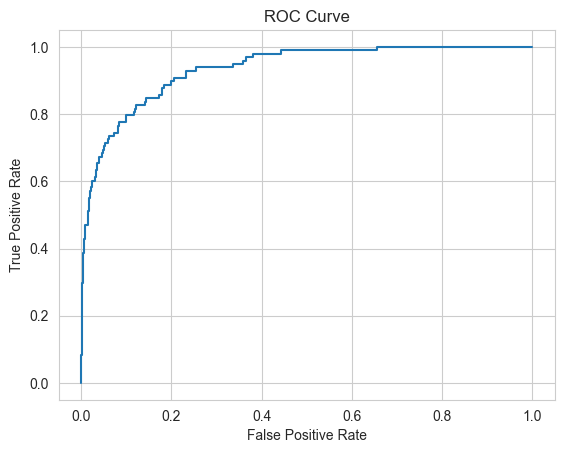

In [42]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, mse)

plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

In [1]:
from sklearn.metrics import recall_score

recall = recall_score(y_test, y_pred)

print("Detection Rate (Recall):", recall)

NameError: name 'y_test' is not defined